Geoinformatik 2 – GIS Analyse
# **Übung 7** · Punktmusteranalyse: Deskriptive räumliche Analyse und Dichtebasierte Methoden
Prof. Dr. Yu Feng

## Lernziele
- Punktmuster visualisieren
- Dichtanalyse

## Umgebung und Daten

Das Notebook erkennt Google Colab automatisch und installiert dort fehlende Pakete. Fehlende Daten werden automatisch heruntergeladen: lokal nach `Uebung7/data`, in Colab nach `/content/data`. Vorhandene Dateien bleiben erhalten; ein Upload ist nicht erforderlich.

Lokal starten Sie Jupyter im Repository oder im Ordner `Uebung7` und installieren bei Bedarf die Pakete im verwendeten Notebook-Kernel:

`%pip install numpy pandas geopandas seaborn contextily matplotlib shapely pointpats libpysal mapclassify folium`

Für die Daten und die Kartenkacheln ist eine Internetverbindung erforderlich. Führen Sie die Zellen der Reihe nach aus.

In [44]:
import importlib.util
import json
import subprocess
import sys
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in ("google", "google.colab"):
        raise
    in_colab = False
else:
    in_colab = True

packages = [
    "numpy", "pandas", "geopandas", "seaborn", "contextily", "matplotlib",
    "shapely", "pointpats", "libpysal", "mapclassify", "folium",
]
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    if not in_colab:
        raise ModuleNotFoundError(
            "Fehlende Pakete im Notebook-Kernel. Installieren Sie diese mit: %pip install "
            + " ".join(missing)
        )
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    importlib.invalidate_caches()

if in_colab:
    data_dir = Path("/content/data")
elif Path.cwd().name == "Uebung7":
    data_dir = Path.cwd() / "data"
elif (Path.cwd() / "Uebung7").is_dir():
    data_dir = Path.cwd() / "Uebung7" / "data"
else:
    raise FileNotFoundError("Jupyter bitte im Repository oder im Ordner Uebung7 starten.")
data_dir.mkdir(parents=True, exist_ok=True)
csv_path = data_dir / "tokyo_clean.csv"
boundary_path = data_dir / "Greater_Tokyo_Area.geojson"

csv_url = "https://raw.githubusercontent.com/gdsbook/book/master/data/tokyo/tokyo_clean.csv"
if not csv_path.is_file():
    with urlopen(csv_url, timeout=120) as response:
        csv_data = response.read()
    with csv_path.open("xb") as output:
        output.write(csv_data)

boundary_url = (
    "https://services.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/"
    "JPN_Boundaries_ECM/FeatureServer/1/query?"
    + urlencode({
        "where": "KEN IN ('08','09','10','11','12','13','14','19')",
        "outFields": "*",
        "outSR": "4326",
        "f": "geojson",
    })
)
if not boundary_path.is_file():
    with urlopen(boundary_url, timeout=120) as response:
        boundary_data = json.load(response)
    if (
        boundary_data.get("type") != "FeatureCollection"
        or boundary_data.get("exceededTransferLimit")
        or len(boundary_data.get("features", [])) != 382
    ):
        raise ValueError(f"Grenzdaten unvollständig oder ungültig: {boundary_data.get('error', 'unerwartete Anzahl Regionen')}")
    with boundary_path.open("x", encoding="utf-8") as output:
        json.dump(boundary_data, output, ensure_ascii=False)

print(f"Umgebung: {'Google Colab' if in_colab else 'lokal'}; Daten: {data_dir.resolve()}")

Umgebung: Google Colab; Daten: /content/data


## Räumliche Punktmuster in Tokyo-Fotografien

Analyse von georeferenzierten Flickr-Fotos zur Untersuchung räumlicher Verteilungen in Städten.

### Bibliotheken laden

In [45]:
import numpy
import pandas
import geopandas as gpd
import seaborn
import contextily
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon

### Daten laden
Datensatz enthält 10.000 Fotografien mit User-ID, Koordinaten (lat/lon + Pseudo-Mercator), Zeitstempel und URL.

In [46]:
db = pandas.read_csv(csv_path)
db.head()

,user_id,longitude,latitude,date_taken,photo/video_page_url,x,y
0,10727420@N00,139.700499,35.674000,2010-04-09 17:26:25.0,http://www.flickr.com/photos/10727420@N00/4545...,1.555139e+07,4.255856e+06
1,8819274@N04,139.766521,35.709095,2007-02-10 16:08:40.0,http://www.flickr.com/photos/8819274@N04/26503...,1.555874e+07,4.260667e+06
2,62068690@N00,139.765632,35.694482,2008-12-21 15:45:31.0,http://www.flickr.com/photos/62068690@N00/3125...,1.555864e+07,4.258664e+06
3,49503094041@N01,139.784391,35.548589,2011-11-11 05:48:54.0,http://www.flickr.com/photos/49503094041@N01/6...,1.556073e+07,4.238684e+06
4,40443199@N00,139.768753,35.671521,2006-04-06 16:42:49.0,http://www.flickr.com/photos/40443199@N00/2482...,1.555899e+07,4.255517e+06


**Hinweis:** Räumliche Information liegt als separate Spalten (longitude, latitude) vor, nicht als Geometry-Objekte.

## Visualisierung von Punktmustern

### Punkte als Scatter-Plot

Einfacher Scatter-Plot zur ersten Übersicht:

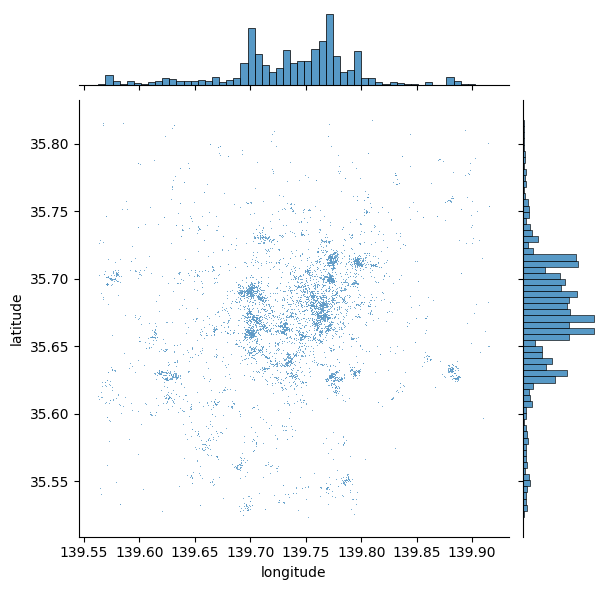

In [47]:
# Generate scatter plot
seaborn.jointplot(x="longitude", y="latitude", data=db, s=0.5);

**Problem:** Keine geografische Kontextinformation und Überlagerung bei hoher Dichte.

**Lösung:** Basemap hinzufügen:

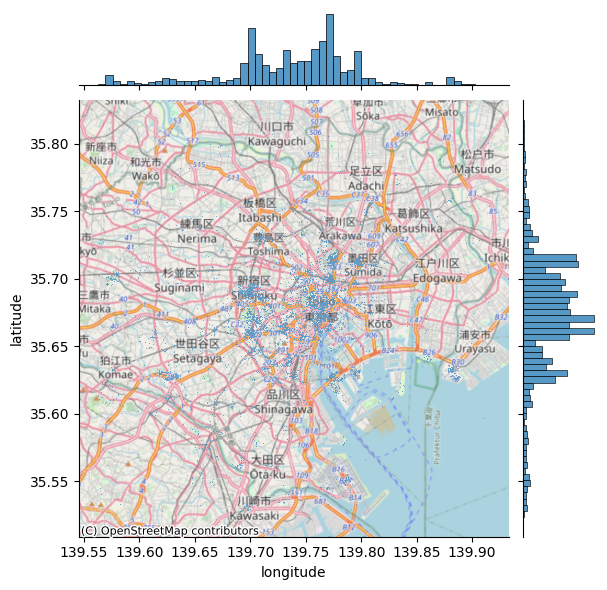

In [48]:
# Generate scatter plot
joint_axes = seaborn.jointplot(
    x="longitude", y="latitude", data=db, s=0.5
)
contextily.add_basemap(
    joint_axes.ax_joint,
    crs="EPSG:4326",
    source=contextily.providers.OpenStreetMap.DE,
);

Die Basemap macht das Muster klarer erkennbar.

## Räumliche Aggregation: Punkt-im-Polygon-Analyse

### GeoJSON-Grenzdaten laden

Lesen der Grenzdaten für die Tokio-Metropolregion:

In [49]:
# GeoJSON-Grenzdaten laden
boundaries = gpd.read_file(boundary_path)
print(f"Grenzen geladen: {len(boundaries)} Regionen")
boundaries.explore(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="&copy; OpenStreetMap contributors",
)

Grenzen geladen: 382 Regionen


### Punkt-im-Polygon: Punkte den Regionen zuordnen

Zuordnung der Fotografiepunkte zu den Grenzen und Zählung:

In [50]:

# Create GeoDataFrame for points
gdf_points = gpd.GeoDataFrame(
    db,
    geometry=gpd.points_from_xy(db.longitude, db.latitude),
    crs="EPSG:4326"
)

# Ensure CRS matches
if boundaries.crs != gdf_points.crs:
    boundaries = boundaries.to_crs(gdf_points.crs)

# Spatial join: assign points to polygons
joined = gpd.sjoin(
    gdf_points,
    boundaries,
    how="inner",
    predicate="within"
)

# Count points per polygon index
point_counts = joined.groupby("index_right").size().reset_index(name="point_count")

# Merge counts back into boundaries, include polygons with zero points
boundaries_with_counts = boundaries.merge(
    point_counts,
    left_index=True,
    right_on="index_right",
    how="left"
)

# Replace NaN with 0
boundaries_with_counts["point_count"] = boundaries_with_counts["point_count"].fillna(0).astype(int)

print(boundaries_with_counts[["index_right", "point_count"]].head())


     index_right  point_count
NaN            0            0
NaN            1            0
NaN            2            0
NaN            3            0
NaN            4            0


### Visualisierung der Intensity-Choropleth-Karte

Darstellung der Punktdichte nach Regionen:

In [51]:
cells_with_points = boundaries_with_counts[boundaries_with_counts["point_count"] > 0]
cells_with_points.explore(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="&copy; OpenStreetMap contributors",
    column="point_count",
    cmap="viridis",
    scheme="naturalbreaks",
    k=5,
    legend=True
)

### Intensity berechnen: Punktdichte pro Region

Berechnung der Intensität (Punkte pro Fläche):

In [52]:
# Statistiken zusammenführen
region_stats = boundaries.copy()
region_stats = region_stats.reset_index(drop=True)
region_stats["point_count"] = region_stats.index.map(
    point_counts.set_index("index_right")["point_count"]
).fillna(0).astype(int)

# Intensity: Punkte pro km²
region_stats["intensity"] = region_stats["point_count"] / (region_stats["SUM_AREA"] / 1_000_000)

# Übersicht
print("\nRegionale Statistiken:")
print(region_stats[["point_count", "SUM_AREA", "intensity"]].describe())


Regionale Statistiken:
       point_count     SUM_AREA     intensity
count   382.000000   382.000000  3.820000e+02
mean     25.772251    96.522783  1.671310e+06
std     141.663377   129.357509  1.047443e+07
min       0.000000     4.056794  0.000000e+00
25%       0.000000    22.849361  0.000000e+00
50%       0.000000    50.270465  0.000000e+00
75%       0.000000   122.812453  0.000000e+00
max    1469.000000  1448.962369  1.152795e+08


In [53]:
cells_with_dens = region_stats[region_stats["intensity"] > 0].copy()

cells_with_dens.explore(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="&copy; OpenStreetMap contributors",
    column="intensity",
    cmap="viridis",
    scheme="naturalbreaks",
    k=5,
    legend=True
)

In [54]:
# Top 10 Regionen nach Intensität
top_regions = region_stats.nlargest(10, "intensity")[
    ["NAME_1","point_count", "SUM_AREA", "intensity"]
].copy()
print("\nTop 10 Regionen nach Fotografieintensität:")
print(top_regions.round(2))


Top 10 Regionen nach Fotografieintensität:
          NAME_1  point_count  SUM_AREA     intensity
235   Chiyoda-ku         1310     11.36  1.152795e+08
240     Taito-ku          941     10.09  9.330006e+07
236      Chuo-ku          765      8.97  8.532202e+07
247   Shibuya-ku         1093     15.12  7.229981e+07
237    Minato-ku         1469     20.71  7.093995e+07
238  Shinjuku-ku          740     18.27  4.050685e+07
239    Bunkyo-ku          258     11.37  2.269295e+07
241    Sumida-ku          204     13.74  1.484696e+07
244    Meguro-ku          198     14.84  1.334386e+07
250   Toshima-ku          158     12.97  1.218105e+07


### Dichte durch Hexbinning

Bei starker Überlagerung: Hexagonales Raster zur Aggregation nutzen.
Hexagone bieten weniger Verzerrung und gleichmäßigere Nachbarschaft als Quadrate.

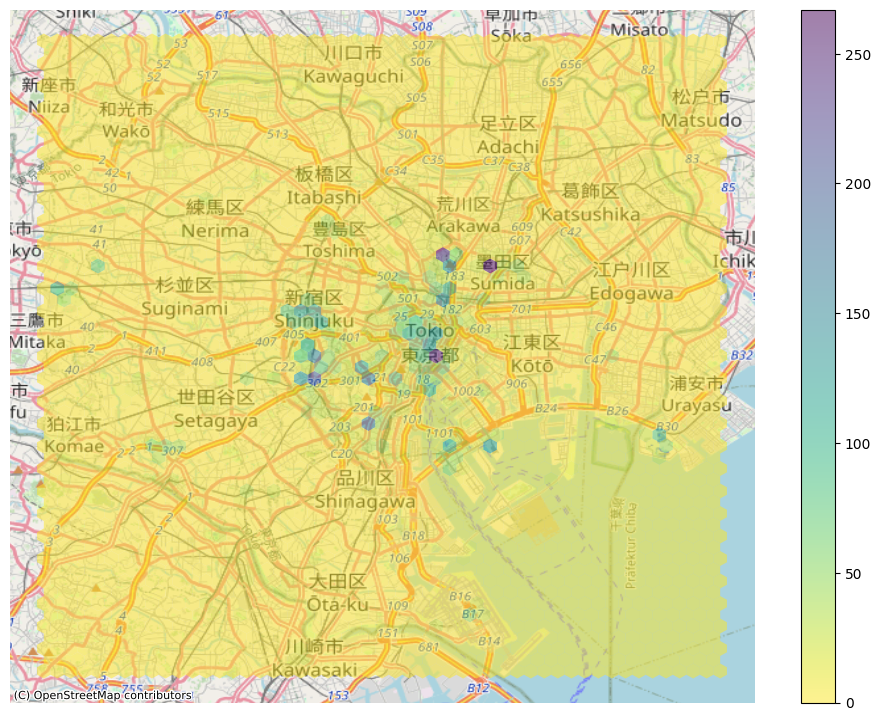

In [55]:
# Set up figure and axis
f, ax = plt.subplots(1, figsize=(12, 9))
# Generate and add hexbin with 50 hexagons in each
# dimension, no borderlines, half transparency,
# and the reverse viridis colormap
hb = ax.hexbin(
    db["x"],
    db["y"],
    gridsize=50,
    linewidths=0,
    alpha=0.5,
    cmap="viridis_r",
)
# Add basemap
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
# Add colorbar
plt.colorbar(hb)
# Remove axes
ax.set_axis_off()

In [56]:
# ---- Build GeoDataFrame from hexbin result ----

# Centers of each hexagon
offsets = hb.get_offsets()          # shape (N, 2)

# Template hexagon (vertices around (0, 0))
base_hex = hb.get_paths()[0].vertices  # shape (7, 2), closed ring

# Build shapely Polygons for each hex
polygons = [Polygon(base_hex + xy) for xy in offsets]

# Values per hex (counts or aggregated values)
values = hb.get_array()            # length N

# Create GeoDataFrame; assume x/y are EPSG:3857
hex_gdf = gpd.GeoDataFrame(
    {"value": values},
    geometry=polygons,
    crs="EPSG:3857"
)

# Reproject to WGS84 for web mapping and save as GeoJSON
hex_gdf_4326 = hex_gdf.to_crs(epsg=4326)
#hex_gdf_4326.to_file("hexbin.geojson", driver="GeoJSON")
hex_gdf_4326.explore(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="&copy; OpenStreetMap contributors",
    column="value",
    cmap="viridis_r",
    legend=True,
    style_kwds={"color": "#555555", "weight": 0.6}
)

Hexbinning zeigt deutlich lokalisierte Hotspots.

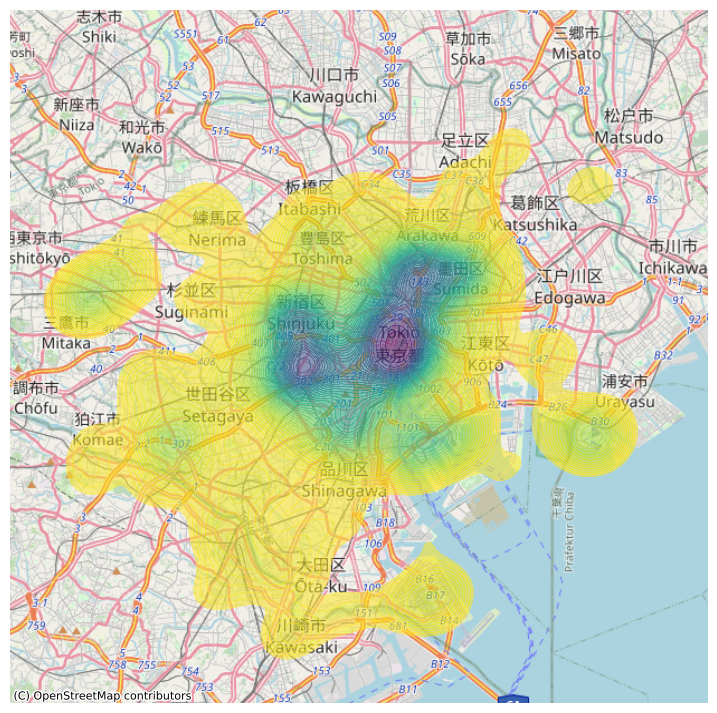

In [57]:
# Set up figure and axis
f, ax = plt.subplots(1, figsize=(9, 9))
# Generate and add KDE with a shading of 50 gradients
# coloured contours, 75% of transparency,
# and the reverse viridis colormap
seaborn.kdeplot(
    x="x",
    y="y",
    data=db,
    n_levels=50,
    fill=True,
    alpha=0.55,
    cmap="viridis_r",
)
# Add basemap
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
# Remove axes
ax.set_axis_off()

KDE erzeugt glattere Übergänge zwischen Dichtegebieten.

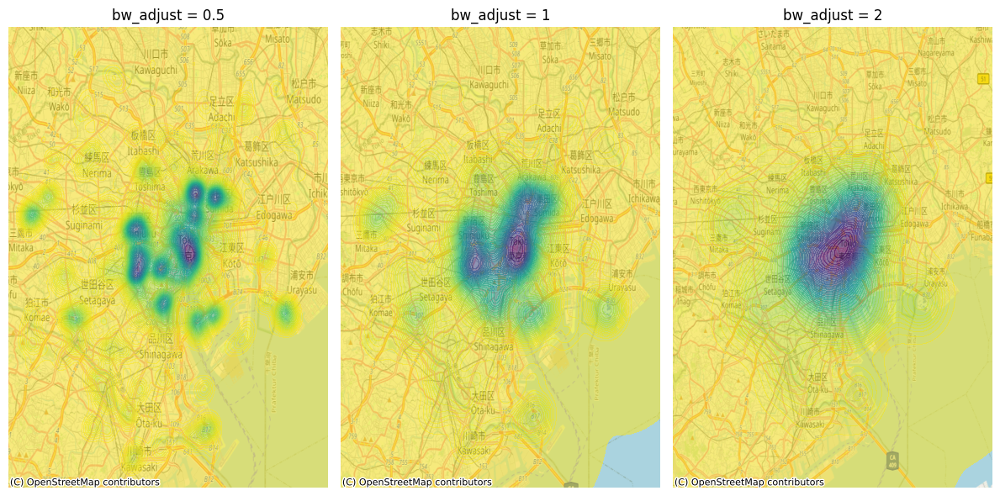

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import contextily

# Bandwidths festlegen
bandwidths = [0.5, 1, 2]

fig, axes = plt.subplots(1, len(bandwidths), figsize=(4*len(bandwidths), 6))

# predefine global contour levels (0 to 1 normalized)
levels = np.linspace(0, 1, 50)

for ax, bw in zip(axes, bandwidths):
    seaborn.kdeplot(
        x="x",
        y="y",
        data=db,
        bw_adjust=bw,
        fill=True,
        alpha=0.55,
        cmap="viridis_r",
        levels=levels,
        thresh=0,
        ax=ax
    )

    contextily.add_basemap(ax, source=contextily.providers.OpenStreetMap.DE)
    ax.set_title(f"bw_adjust = {bw}")
    ax.set_axis_off()

plt.tight_layout()


## Zentrographie

Analyse von Zentralität: Lage und Streuung des Punktmusters durch kompakte Maße beschreiben.

### Zentrale Tendenz

**Mean Center:** Durchschnitt der Koordinaten  
**Median Center:** Mittlerer Punkt (je 50% über/unter bzw. links/rechts)

In [59]:
from pointpats import centrography

In [60]:
mean_center = centrography.mean_center(db[["x", "y"]])
med_center = centrography.euclidean_median(db[["x", "y"]])

Visualisierung:

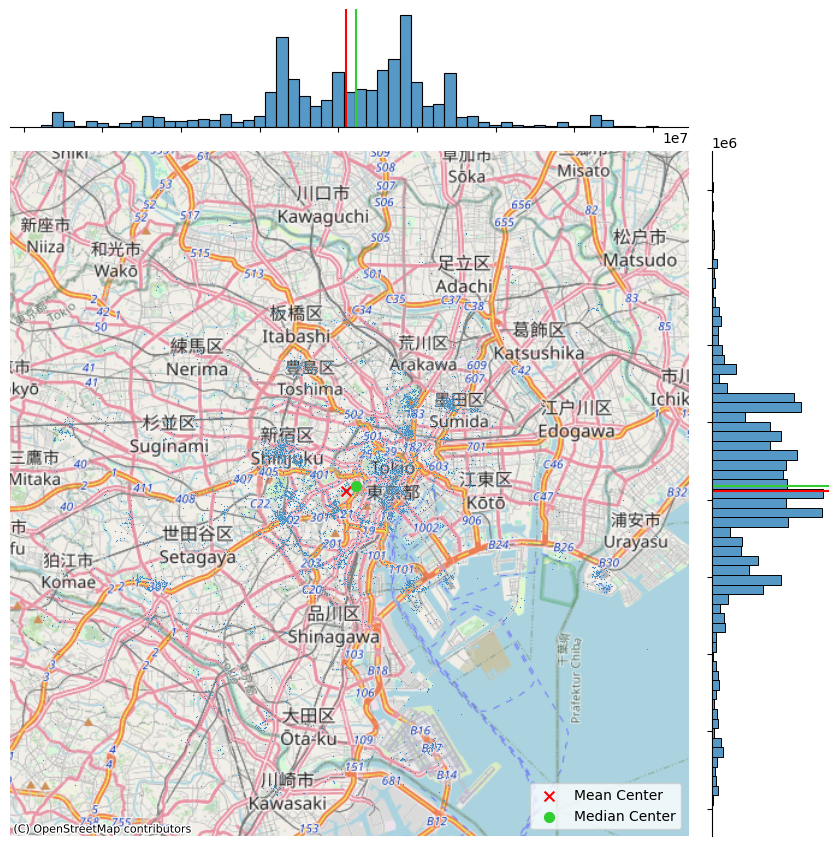

In [61]:
# Generate scatterplot
joint_axes = seaborn.jointplot(
    x="x", y="y", data=db, s=0.75, height=9
)
# Add mean point and marginal lines
joint_axes.ax_joint.scatter(
    *mean_center, color="red", marker="x", s=50, label="Mean Center"
)
joint_axes.ax_marg_x.axvline(mean_center[0], color="red")
joint_axes.ax_marg_y.axhline(mean_center[1], color="red")
# Add median point and marginal lines
joint_axes.ax_joint.scatter(
    *med_center,
    color="limegreen",
    marker="o",
    s=50,
    label="Median Center"
)
joint_axes.ax_marg_x.axvline(med_center[0], color="limegreen")
joint_axes.ax_marg_y.axhline(med_center[1], color="limegreen")
# Legend
joint_axes.ax_joint.legend()
# Add basemap
contextily.add_basemap(
    joint_axes.ax_joint, source=contextily.providers.OpenStreetMap.DE
)
# Clean axes
joint_axes.ax_joint.set_axis_off()
# Display
plt.show()

Die Diskrepanz entsteht durch periphere Cluster (West/Süd-Tokyo), die den Mittelwert verzerren.

**Standard Distance:** Wurzel aus der mittleren quadrierten Entfernung zum Mean Center. In der folgenden Karte ist sie als orangefarbener Kreis dargestellt: Mittelpunkt = Mean Center, Radius = Standard Distance.


In [62]:
std_distance = centrography.std_distance(db[["x", "y"]])
print(f"Standard Distance: {std_distance:.1f} m")


Standard Distance: 8778.2 m


**Standard-Ellipse:** Visualisiert Zentrum, Streuung und Orientierung des Musters. Zum Vergleich zeigt der orangefarbene Kreis die Standard Distance ohne bevorzugte Richtung.


In [63]:
major, minor, rotation = centrography.ellipse(db[["x", "y"]])

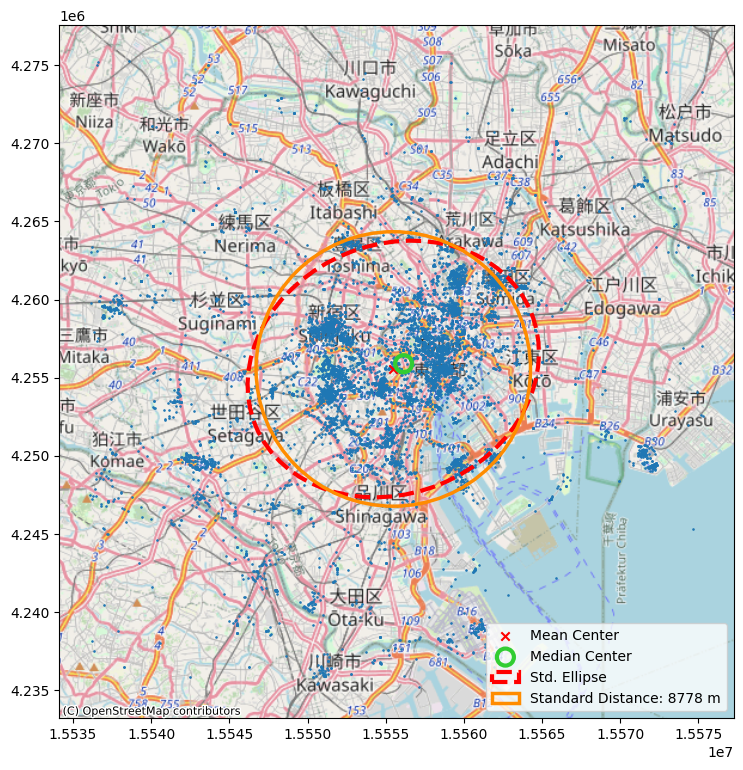

In [64]:
from matplotlib.patches import Ellipse, Circle

# Set up figure and axis
f, ax = plt.subplots(1, figsize=(9, 9))
# Plot photograph points
ax.scatter(db["x"], db["y"], s=0.75)
ax.scatter(*mean_center, color="red", marker="x", label="Mean Center")
ax.scatter(
    *med_center,
    facecolors="none",
    edgecolors="limegreen",
    marker="o",
    s=150,
    linewidths=3,
    label="Median Center",
)

# Construct the standard ellipse using matplotlib
ellipse = Ellipse(
    xy=mean_center,  # center the ellipse on our mean center
    width=major * 2,  # centrography.ellipse only gives half the axis
    height=minor * 2,
    angle=numpy.rad2deg(
        rotation
    ),  # Angles for this are in degrees, not radians
    facecolor="none",
    edgecolor="red",
    linewidth=3,
    linestyle="--",
    label="Std. Ellipse",
)
ax.add_patch(ellipse)

# Standard-Distance-Kreis: gleicher Mittelpunkt, Radius = Standard Distance.
std_circle = Circle(
    xy=mean_center,
    radius=std_distance,
    facecolor="none",
    edgecolor="darkorange",
    linewidth=2.5,
    label=f"Standard Distance: {std_distance:.0f} m",
)
ax.add_patch(std_circle)
ax.set_aspect("equal", adjustable="box")

ax.legend()
# Display
# Add basemap
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
plt.show()

### Ausdehnung

Verschiedene Formen zur Beschreibung der räumlichen Ausdehnung.
Beispiel: Nutzer mit ID `95795770` (aktivster Nutzer).

In [65]:
user = db.query('user_id == "95795770@N00"')
coordinates = user[["x", "y"]].values

**Convex Hull:** Kleinste konvexe Form, die alle Punkte umschließt (keine Einbuchtungen).

In [66]:
convex_hull_vertices = centrography.hull(coordinates)

**Alpha Shape:** Engere Form als Convex Hull. Metapher: Eine kleine Kugel rollt um die Punkte und folgt Einbuchtungen.
Bei zu kleinem Alpha entstehen mehrere Hüllen. `alpha_shape_auto` findet die kleinste zusammenhängende Form.

In [67]:
import libpysal

alpha_shape, alpha, circs = libpysal.cg.alpha_shape_auto(
    coordinates, return_circles=True
)

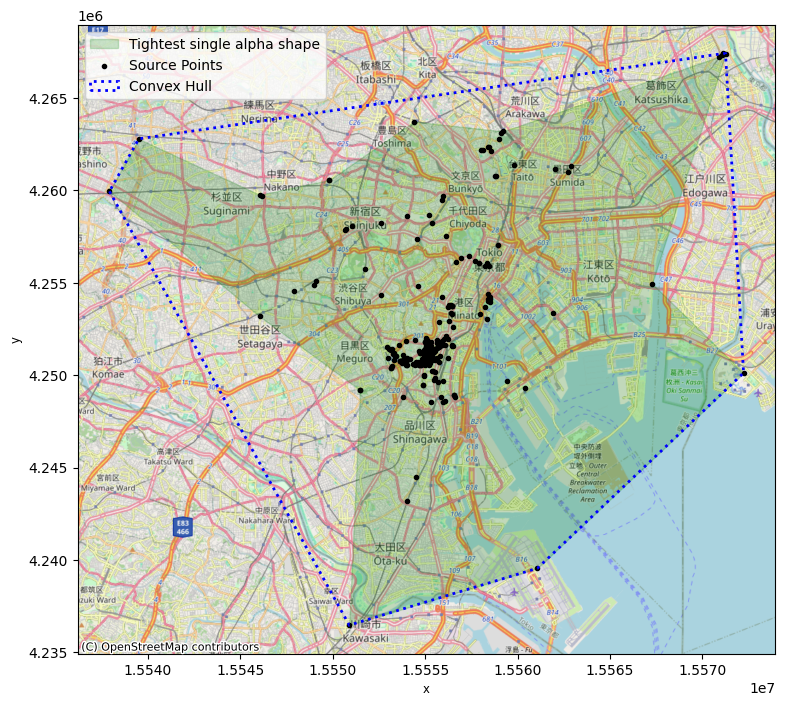

In [68]:
f, ax = plt.subplots(1, 1, figsize=(9, 9))

# Plot a green alpha shape
gpd.GeoSeries(
    [alpha_shape]
).plot(
    ax=ax,
    edgecolor="green",
    facecolor="green",
    alpha=0.2,
    label="Tightest single alpha shape",
)

# Include the points for our prolific user in black
ax.scatter(
    *coordinates.T, color="k", marker=".", label="Source Points"
)

# add a blue convex hull
ax.add_patch(
    plt.Polygon(
        convex_hull_vertices,
        closed=True,
        edgecolor="blue",
        facecolor="none",
        linestyle=":",
        linewidth=2,
        label="Convex Hull",
    )
)

# Add basemap
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
plt.legend();

## Homogenität und Clustering

Analyse der räumlichen Homogenität: Sind Punkte geclustert oder gleichmäßig verteilt?

**Zwei Ansätze:**
1. **Quadrat-Statistiken:** Zählen in regelmäßigen Zellen
2. **Ripley-Funktionen:** Distanzmessungen zwischen Punkten (nächste Woche)

In [69]:
from pointpats import (
    QStatistic,
    random,
)

### CSR generieren

**Poisson-Prozess:** Vollständig zufälliger räumlicher Prozess (CSR) zum Vergleich.
Für reproduzierbare Zufallsmuster verwenden wir feste Seeds (42 und 43). Bei gleichen Daten und Paketversionen bleiben die Ergebnisse beim erneuten Ausführen gleich. Unterschiedliche Paketversionen können andere Zufallsfolgen erzeugen.


In [70]:
import inspect

# Neue pointpats-Versionen verwenden rng, ältere NumPys globalen Zufallsgenerator.
def poisson_with_seed(area, size, seed):
    if "rng" in inspect.signature(random.poisson).parameters:
        return random.poisson(area, size=size, rng=seed)
    previous_state = numpy.random.get_state()
    try:
        numpy.random.seed(seed)
        return random.poisson(area, size=size)
    finally:
        numpy.random.set_state(previous_state)

random_pattern = poisson_with_seed(coordinates, size=len(coordinates), seed=42)


Visualisierung:

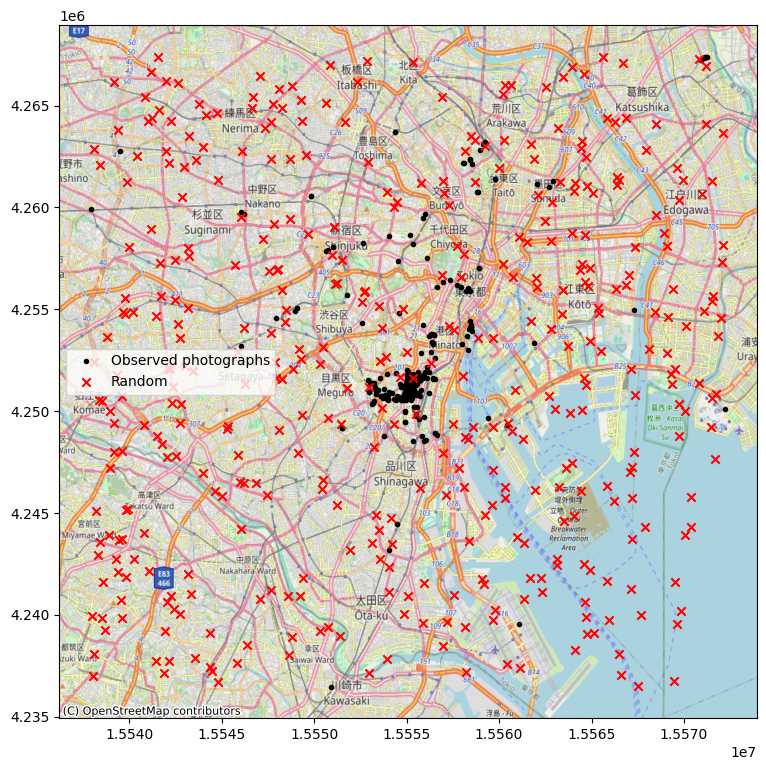

In [71]:
f, ax = plt.subplots(1, figsize=(9, 9))
plt.scatter(
    *coordinates.T,
    color="k",
    marker=".",
    label="Observed photographs"
)
plt.scatter(*random_pattern.T, color="r", marker="x", label="Random")
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
ax.legend(ncol=1, loc="center left")
plt.show()

Standard: Simulation in Bounding Box. Für eingeschränkte Bereiche (z.B. Alpha Shape):

In [72]:
random_pattern_ashape = poisson_with_seed(
    alpha_shape, size=len(coordinates), seed=43
)


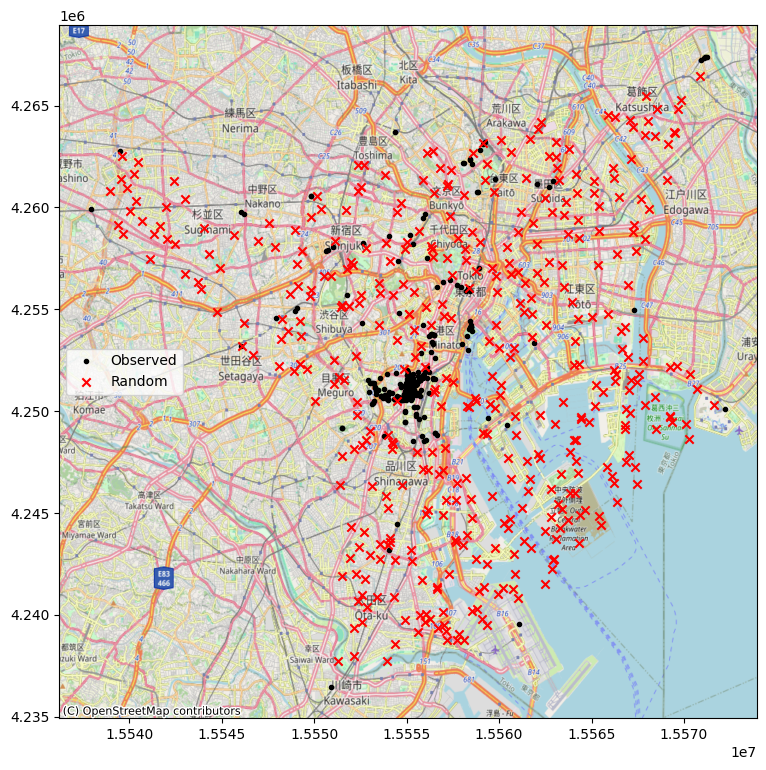

In [73]:
f, ax = plt.subplots(1, figsize=(9, 9))
plt.scatter(*coordinates.T, color="k", marker=".", label="Observed")
plt.scatter(
    *random_pattern_ashape.T, color="r", marker="x", label="Random"
)
contextily.add_basemap(
    ax, source=contextily.providers.OpenStreetMap.DE
)
ax.legend(ncol=1, loc="center left")
plt.show()

### Quadrat-Statistiken

Wir teilen das Rechteck um die Tokyo-Fotografien in ein Raster mit 5 × 5 gleich großen Zellen. Bei einer räumlich gleichmäßigen Verteilung erwarten wir in jeder Zelle gleich viele Punkte.

**Warum ein χ²-Test?** Wir vergleichen beobachtete Punktzahlen mit erwarteten Punktzahlen. Unter der Nullhypothese einer räumlich gleichmäßigen Verteilung ist jede gleich große Zelle gleich wahrscheinlich. Der Pearson-χ²-Test fasst die Abweichungen aller Zellen in einer Zahl zusammen und prüft, ob sie größer sind, als durch Zufall zu erwarten wäre. Bei ausreichend großen erwarteten Zellzahlen folgt diese Prüfgröße näherungsweise einer χ²-Verteilung.

#### 1. Punkte pro Zelle

$O_i$ ist die beobachtete Punktzahl in Zelle $i$. `QStatistic` zeichnet das Raster und liefert mit `qstat.mr.point_location_sta()` die Zellzahlen. Aus diesen berechnen wir anschließend selbst die erwartete Punktzahl, die Abweichungen, das VMR und X².


<Axes: title={'center': 'Quadrat Count'}>

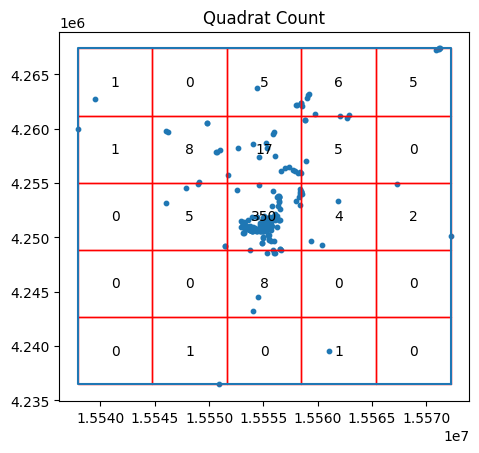

In [74]:
qstat = QStatistic(coordinates, nx=5, ny=5)
qstat.plot()


In [75]:
import numpy as np
import pandas as pd

observed = np.array(list(qstat.mr.point_location_sta().values()))
k = len(observed)
N = observed.sum()
expected = N / k

cell_counts = pd.DataFrame({
    "Beobachtet O_i": observed,
    "Erwartet E_i": expected,
    "Abweichung O_i − E_i": observed - expected,
})
display(cell_counts)
print(f"N = {N}, k = {k}, E_i = N / k = {expected:.3f}")


,Beobachtet O_i,Erwartet E_i,Abweichung O_i − E_i
0,0,16.76,-16.76
1,1,16.76,-15.76
2,0,16.76,-16.76
3,1,16.76,-15.76
4,0,16.76,-16.76
5,0,16.76,-16.76
6,0,16.76,-16.76
7,8,16.76,-8.76
8,0,16.76,-16.76
9,0,16.76,-16.76


N = 419, k = 25, E_i = N / k = 16.760


#### 2. Vom VMR zur χ²-Statistik

Aus der Vorlesung kennen wir das Varianz-Mittelwert-Verhältnis (VMR). Für die Zellzahlen gilt mit dem Mittelwert $\bar{O}=N/k$ und der Stichprobenvarianz $s^2$:

$$s^2=\frac{1}{k-1}\sum_{i=1}^{k}(O_i-\bar{O})^2, \qquad VMR=\frac{s^2}{\bar{O}}$$

VMR ≈ 1 entspricht der erwarteten Streuung im Poisson-Modell. VMR > 1 beschreibt eine stärkere, VMR < 1 eine geringere Streuung. Wie groß muss die Abweichung sein, damit sie statistisch signifikant ist? Dafür erweitern wir die Betrachtung um die χ²-Statistik.

Bei gleich großen Zellen ist die erwartete Punktzahl $E_i=\bar{O}$. Die Pearson-χ²-Statistik lautet:

$$X^2=\sum_{i=1}^{k}\frac{(O_i-E_i)^2}{E_i}$$

Setzen wir $E_i=\bar{O}$ ein, erkennen wir den Zusammenhang mit dem VMR:

$$X^2=\frac{\sum_{i=1}^{k}(O_i-\bar{O})^2}{\bar{O}}
=\frac{(k-1)s^2}{\bar{O}}
=(k-1)\cdot VMR$$

Beide Kennzahlen beruhen also auf denselben Abweichungen der Zellzahlen. X² ist das VMR multipliziert mit $k-1$. Dieser Zusammenhang gilt hier, weil alle Zellen dieselbe erwartete Punktzahl haben und wir die Stichprobenvarianz mit dem Nenner $k-1$ verwenden.

**df = Degrees of Freedom (Freiheitsgrade).** Die Gesamtpunktzahl $N$ ist fest. Sind die Punktzahlen in $k-1$ Zellen bekannt, ist die letzte Zellzahl bereits bestimmt. Deshalb gilt $df=k-1$, bei 25 Zellen also $df=24$ und $X^2=24\cdot VMR$.

Wir berechnen zuerst das VMR und daraus X². Zum Vergleich berechnen wir X² auch direkt aus seiner Summenformel. Der anschließende p-Wert $P(\chi^2_{df}\geq X^2)$ zeigt, ob X² ungewöhnlich groß ist; diese Wahrscheinlichkeit liefert SciPy.

**Was bedeutet `chi2_distribution.sf(chi2_manual, df_manual)`?**

`chi2_distribution` ist die χ²-Verteilung aus SciPy, die wir mit `from scipy.stats import chi2 as chi2_distribution` importieren. `sf` steht für **Survival Function**. Sie gibt die Wahrscheinlichkeit rechts von einem angegebenen Wert zurück:

$$\text{sf}(x, df)=P(\chi^2_{df}\geq x)=1-F(x)$$

Dabei ist $F(x)$ die kumulative Verteilungsfunktion, also die Wahrscheinlichkeit links von $x$.

- `chi2_manual`: unser berechneter X²-Wert, ab dem die rechte Fläche beginnt.
- `df_manual`: die Freiheitsgrade der verwendeten χ²-Verteilung.
- Rückgabewert: der **p-Wert**, also unter der Nullhypothese die Wahrscheinlichkeit für einen mindestens so großen X²-Wert.

Beispiel: `chi2_distribution.sf(36.415, 24)` ergibt ungefähr `0.05`. Bei 24 Freiheitsgraden liegen also etwa 5 % der χ²-Verteilung rechts von 36,415. Ein kleiner p-Wert bedeutet, dass eine so große Abweichung unter der Nullhypothese selten wäre. Er ist nicht die Wahrscheinlichkeit, dass die Nullhypothese wahr ist.

Wir verwenden `sf` direkt, weil es die rechte Restwahrscheinlichkeit auch bei sehr kleinen p-Werten numerisch genauer berechnet als `1 - cdf(...)`.


In [76]:
from scipy.stats import chi2 as chi2_distribution

# Varianz und Variance-to-Mean-Ratio berechnen
variance_manual = np.var(observed, ddof=1)
vmr_manual = variance_manual / np.mean(observed)

df_manual = k - 1
chi2_from_vmr = df_manual * vmr_manual
chi2_manual = ((observed - expected) ** 2 / expected).sum()

# Rechte Fläche der χ²-Verteilung ab unserem X²-Wert = p-Wert
p_manual = chi2_distribution.sf(chi2_manual, df_manual)

print(f"VMR = s² / Mittelwert = {vmr_manual:.6f}")
print(f"df = k − 1 = {df_manual}")
print(f"X² aus VMR = {df_manual} × {vmr_manual:.6f} = {chi2_from_vmr:.6f}")
print(f"X² aus der Summenformel = {chi2_manual:.6f}")
print(f"p = {p_manual:.6g}")


VMR = s² / Mittelwert = 288.520684
df = k − 1 = 24
X² aus VMR = 24 × 288.520684 = 6924.496420
X² aus der Summenformel = 6924.496420
p = 0


#### 3. Berechnung mit QStatistic

`QStatistic` berechnet X², Freiheitsgrade und p-Wert direkt. Aus X² / df erhalten wir außerdem das VMR.


In [77]:
chi2_software = qstat.chi2
df_software = qstat.df
p_software = qstat.chi2_pvalue
vmr_software = chi2_software / df_software

print(f"X² = {chi2_software:.6f}")
print(f"df = {df_software}")
print(f"p = {p_software:.6g}")
print(f"VMR = {vmr_software:.6f}")


X² = 6924.496420
df = 24
p = 0
VMR = 288.520684


#### 4. Vergleich

Beide Rechnungen verwenden dieselben Zellzahlen. Deshalb sollten ihre Ergebnisse bis auf Rundungsfehler übereinstimmen.


In [78]:
comparison = pd.DataFrame({
    "Eigene Formel": [chi2_manual, df_manual, p_manual, vmr_manual],
    "QStatistic": [chi2_software, df_software, p_software, vmr_software],
}, index=["X²", "df", "p", "VMR"])
comparison["Absolute Differenz"] = abs(comparison["Eigene Formel"] - comparison["QStatistic"])
display(comparison)

if p_manual < 0.05:
    print("p < 0,05: Die Zellzahlen weichen signifikant von einer gleichmäßigen Verteilung ab.")
else:
    print("p ≥ 0,05: Der Test zeigt keine signifikante Abweichung von einer gleichmäßigen Verteilung.")


,Eigene Formel,QStatistic,Absolute Differenz
X²,6924.496420,6924.496420,0.000000e+00
df,24.000000,24.000000,0.000000e+00
p,0.000000,0.000000,0.000000e+00
VMR,288.520684,288.520684,5.684342e-14


p < 0,05: Die Zellzahlen weichen signifikant von einer gleichmäßigen Verteilung ab.


VMR > 1 bedeutet, dass die Zellzahlen stärker streuen als bei einem Poisson-Modell; VMR < 1 bedeutet eine geringere Streuung. Ein großer p-Wert beweist keine Zufälligkeit. Der hier verwendete χ²-Test prüft große Abweichungen der Zellzahlen von gleichen erwarteten Häufigkeiten.

#### 5. Vergleich mit den Zufallsmustern

Die drei Karten zeigen die Tokyo-Fotografien und die beiden Zufallsmuster mit ihrem jeweiligen 5 × 5-Raster und den Zellzahlen. Die Darstellung erfolgt direkt mit `QStatistic.plot()`. Unter jeder Karte stehen die Ergebnisse von `QStatistic`: X², p-Wert und VMR (= X² / df). Mit den oben festgelegten Seeds sind die Zufallsmuster bei gleichen Daten und Paketversionen reproduzierbar.


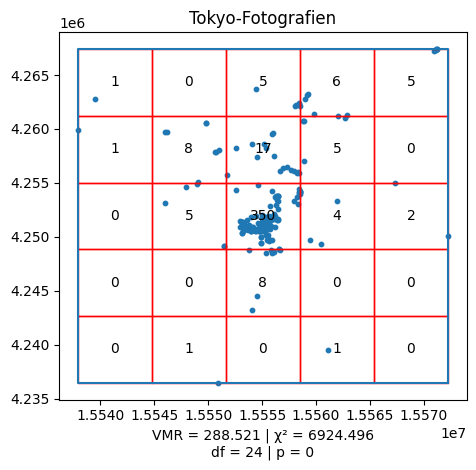

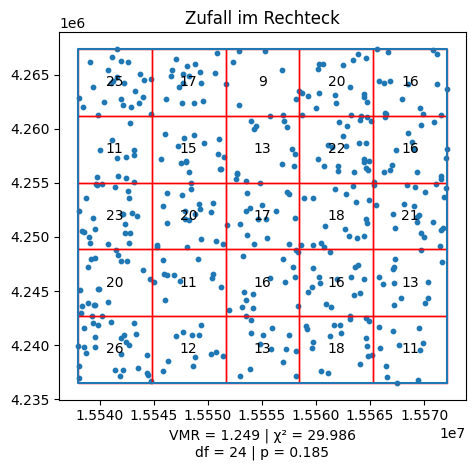

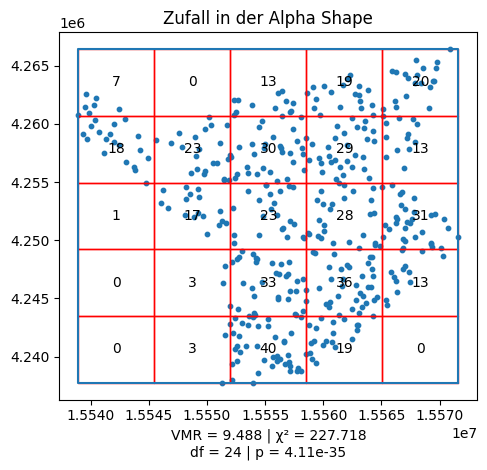

In [79]:
patterns = {
    "Tokyo-Fotografien": coordinates,
    "Zufall im Rechteck": random_pattern,
    "Zufall in der Alpha Shape": random_pattern_ashape,
}

for name, points in patterns.items():
    stat = QStatistic(points, nx=5, ny=5)
    stat.plot(title=name)
    plt.xlabel(
        f"VMR = {stat.chi2 / stat.df:.3f} | χ² = {stat.chi2:.3f}\n"
        f"df = {stat.df} | p = {stat.chi2_pvalue:.3g}"
    )
    plt.tight_layout()
    plt.show()


Im Rechteck ist die Annahme gleicher erwarteter Zellzahlen für das dort simulierte Zufallsmuster passend. In der Alpha Shape liegen dagegen Teile der Randzellen außerhalb der Simulationsfläche. Dort können keine Punkte entstehen. Gleiche erwartete Zellzahlen passen deshalb nicht zu diesem Gebiet; auch ein zufälliges Muster kann hier einen kleinen p-Wert ergeben.

Die χ²-Näherung setzt ausreichend große erwartete Zellzahlen voraus (Faustregel: mindestens 5 pro Zelle). Alle Ergebnisse beziehen sich auf das gewählte 5 × 5-Raster.


## Daten & Referenz
- Point Pattern Analysis — Geographic Data Science with Python: https://geographicdata.science/book/notebooks/08_point_pattern_analysis.html
- Fotodaten: https://github.com/gdsbook/book/tree/master/data/tokyo
- Gemeindegrenzen: Esri Japan, Japan Municipality Boundaries ECM (2015 Census), https://www.arcgis.com/home/item.html?id=83d67d4dca074180ab1e11dd6b399919 (Esri Master License Agreement; Dienst angekündigt bis Dezember 2027)